In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
np.random.seed(42)

n = 200

customer_id = range(1, n + 1)

signup_date = pd.date_range(start="2024-01-01",periods=n,freq="D")

last_purchase_date = signup_date + pd.to_timedelta(np.random.randint(1, 300, n),unit="D")

total_spend = np.random.exponential(scale=5000,size=n)

visits = np.random.randint(1, 30, n)

churned = np.random.randint(0, 2, n)

In [ ]:
df = pd.DataFrame({
    "customer_id": customer_id,
    "signup_date": signup_date,
    "last_purchase_date": last_purchase_date,
    "total_spend": total_spend,
    "visits": visits,
    "churned": churned})

In [4]:
df.head()


,customer_id,signup_date,last_purchase_date,total_spend,visits,churned
0,1,2024-01-01,2024-04-13,5659.258671,14,0
1,2,2024-01-02,2024-09-29,83.634738,2,0
2,3,2024-01-03,2024-04-19,3588.152923,29,0
3,4,2024-01-04,2024-03-16,1284.120735,19,1
4,5,2024-01-05,2024-07-12,5180.621708,18,0


In [5]:
df.shape

(200, 6)

In [19]:
df["signup_year"] = df["signup_date"].dt.year

df["signup_month"] = df["signup_date"].dt.month

df["signup_weekday"] = df["signup_date"].dt.day_of_week

In [7]:
df[["signup_date", "signup_year", "signup_month", "signup_weekday"]].head()

,signup_date,signup_year,signup_month,signup_weekday
0,2024-01-01,2024,1,0
1,2024-01-02,2024,1,1
2,2024-01-03,2024,1,2
3,2024-01-04,2024,1,3
4,2024-01-05,2024,1,4


In [8]:
df["days_since_last_purchase"] = (
    pd.Timestamp.today().normalize() - df["last_purchase_date"]
).dt.days

In [9]:
df[["last_purchase_date", "days_since_last_purchase"]].head()

,last_purchase_date,days_since_last_purchase
0,2024-04-13,936
1,2024-09-29,767
2,2024-04-19,930
3,2024-03-16,964
4,2024-07-12,846


In [10]:
df["spend_per_visit"] = df["total_spend"] / df["visits"]

In [11]:
df[["total_spend", "visits", "spend_per_visit"]].head()

,total_spend,visits,spend_per_visit
0,5659.258671,14,404.232762
1,83.634738,2,41.817369
2,3588.152923,29,123.729411
3,1284.120735,19,67.585302
4,5180.621708,18,287.812317


In [12]:
df["log_total_spend"] = np.log1p(df["total_spend"])

In [13]:
df[["total_spend", "log_total_spend"]].head()

,total_spend,log_total_spend
0,5659.258671,8.641225
1,83.634738,4.438345
2,3588.152923,8.185671
3,1284.120735,7.158608
4,5180.621708,8.552873


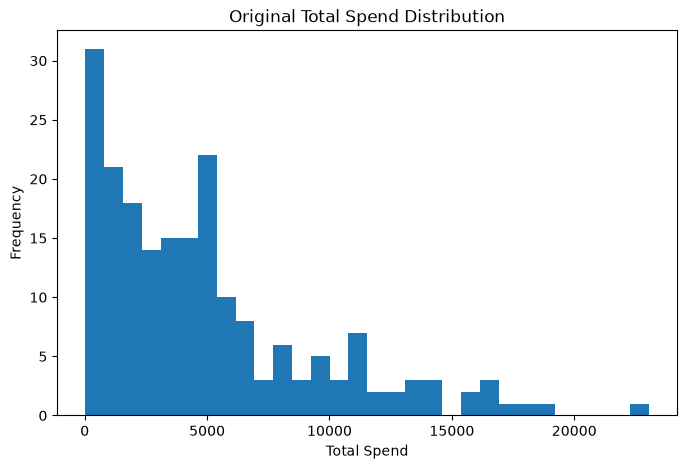

In [14]:
plt.figure(figsize=(8, 5))

plt.hist(df["total_spend"], bins=30)

plt.title("Original Total Spend Distribution")
plt.xlabel("Total Spend")
plt.ylabel("Frequency")

plt.show()

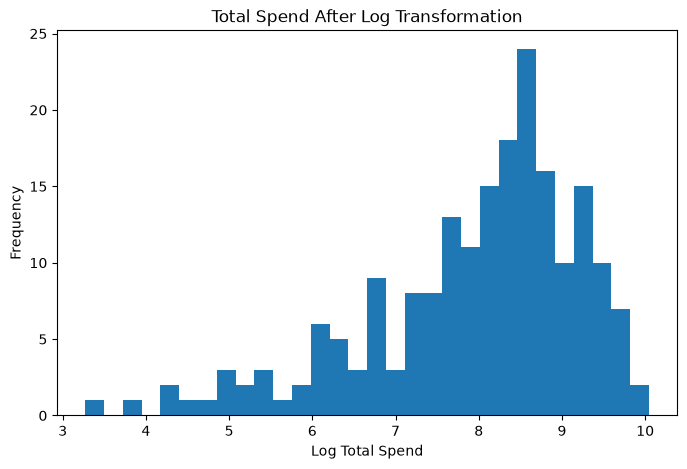

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(df["log_total_spend"], bins=30)

plt.title("Total Spend After Log Transformation")
plt.xlabel("Log Total Spend")
plt.ylabel("Frequency")

plt.show()

In [16]:
new_features = [
    "signup_year",
    "signup_month",
    "signup_weekday",
    "days_since_last_purchase",
    "spend_per_visit",
    "log_total_spend"
]

correlation = df[new_features].corrwith(df["churned"])

correlation_df = correlation.reset_index()

correlation_df.columns = ["Feature", "Correlation"]

correlation_df

,Feature,Correlation
0,signup_year,NaN
1,signup_month,-0.027409
2,signup_weekday,0.034475
3,days_since_last_purchase,-0.020342
4,spend_per_visit,0.081645
5,log_total_spend,-0.037441


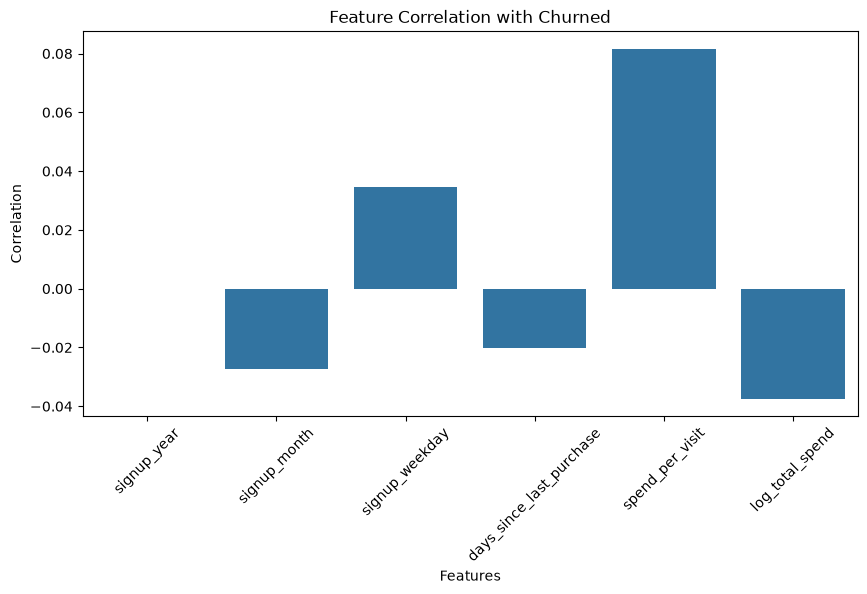

In [17]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=correlation_df,
    x="Feature",
    y="Correlation"
)

plt.xticks(rotation=45)
plt.title("Feature Correlation with Churned")
plt.xlabel("Features")
plt.ylabel("Correlation")

plt.show()

In [18]:
correlation_df["Absolute_Correlation"] = (
    correlation_df["Correlation"].abs()
)

correlation_df.sort_values(
    by="Absolute_Correlation",
    ascending=False
)

,Feature,Correlation,Absolute_Correlation
4,spend_per_visit,0.081645,0.081645
5,log_total_spend,-0.037441,0.037441
2,signup_weekday,0.034475,0.034475
1,signup_month,-0.027409,0.027409
3,days_since_last_purchase,-0.020342,0.020342
0,signup_year,NaN,NaN


## Result

1. Spend_per_visit has the highest absolute correlation (0.081645) with the churned target among the new features.

2. It represents the average amount spent by a customer per visit.

3. However, the correlation is very weak, and the churned values are randomly generated, so further validation is required.